In [1]:
import torch, sys
sys.path.append("..")          # lets the notebook import from src/
from src import config

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.randn(1000, 1000, device="cuda")
    print("GPU test OK:", (x @ x).shape)

print("Grid:", config.N, "x", config.N, "| vocab:", config.VOCAB_SIZE)

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 2050
GPU test OK: torch.Size([1000, 1000])
Grid: 6 x 6 | vocab: 8


In [ ]:
#setup
import os, sys, time, math, json
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # go to project root (safe to re-run)
sys.path.append(os.getcwd())

import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

from src.config import N, NUM_CELLS, SEP, VOCAB_SIZE
from src.dataset import load
from src.sudoku import is_valid, count_violations, matches_clues, show

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device, "| grid:", N, "x", N)

Using: cuda | grid: 6 x 6


In [ ]:
#Load Data
tr_p, tr_s = load("train")
va_p, va_s = load("val")
te_p, te_s = load("test")

def to_t(a):
    return torch.tensor(a.reshape(len(a), -1), dtype=torch.long, device=device)

Xtr, Ytr = to_t(tr_p), to_t(tr_s)
Xva, Yva = to_t(va_p), to_t(va_s)
print("train:", Xtr.shape, "| val:", Xva.shape)
print("puzzle  :", Xtr[0].tolist())
print("solution:", Ytr[0].tolist())

train: torch.Size([19999, 36]) | val: torch.Size([1000, 36])
puzzle  : [5, 0, 6, 0, 0, 2, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 0, 0, 0, 5, 0, 5, 2, 1, 0, 0, 0, 0, 0, 0, 2, 3]
solution: [5, 1, 6, 4, 3, 2, 2, 4, 3, 6, 5, 1, 6, 2, 5, 3, 1, 4, 1, 3, 4, 2, 6, 5, 3, 5, 2, 1, 4, 6, 4, 6, 1, 5, 2, 3]


In [4]:
#Build the sequence
def make_seq(puz, sol):
    sep = torch.full((puz.shape[0], 1), SEP, dtype=torch.long, device=puz.device)
    return torch.cat([puz, sep, sol], dim=1)          # (B, 73)

seq = make_seq(Xtr[:2], Ytr[:2])
print(seq.shape)
print(seq[0].tolist())

torch.Size([2, 73])
[5, 0, 6, 0, 0, 2, 0, 4, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 0, 0, 0, 5, 0, 5, 2, 1, 0, 0, 0, 0, 0, 0, 2, 3, 7, 5, 1, 6, 4, 3, 2, 2, 4, 3, 6, 5, 1, 6, 2, 5, 3, 1, 4, 1, 3, 4, 2, 6, 5, 3, 5, 2, 1, 4, 6, 4, 6, 1, 5, 2, 3]


In [5]:
#Embeddings
D_MODEL, N_HEADS, N_LAYERS, D_FF = 128, 4, 4, 512
SEQ_LEN = 2 * NUM_CELLS                                # 72

tok_emb = nn.Embedding(VOCAB_SIZE, D_MODEL).to(device)
pos_emb = nn.Embedding(SEQ_LEN, D_MODEL).to(device)

x = seq[:, :-1]                                        # (2, 72) model input
pos = torch.arange(x.shape[1], device=device)          # [0, 1, ..., 71]
h = tok_emb(x) + pos_emb(pos)                          # (2, 72, 128)
print(x.shape, "->", h.shape)

torch.Size([2, 72]) -> torch.Size([2, 72, 128])


In [6]:
#Causal self-attention
class CausalSelfAttention(nn.Module):
    def __init__(self, d, h):
        super().__init__()
        self.h, self.dk = h, d // h
        self.qkv = nn.Linear(d, 3 * d)       # makes Q, K, V in one go
        self.out = nn.Linear(d, d)

    def forward(self, x):                                   # x: (B, T, D)
        B, T, D = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)              # each (B, T, D)
        q = q.view(B, T, self.h, self.dk).transpose(1, 2)   # (B, h, T, dk)
        k = k.view(B, T, self.h, self.dk).transpose(1, 2)
        v = v.view(B, T, self.h, self.dk).transpose(1, 2)

        att = (q @ k.transpose(-2, -1)) / math.sqrt(self.dk)   # (B, h, T, T)
        mask = torch.tril(torch.ones(T, T, device=x.device)).bool()
        att = att.masked_fill(~mask, float("-inf"))            # block the future
        att = att.softmax(dim=-1)

        y = att @ v                                          # (B, h, T, dk)
        y = y.transpose(1, 2).contiguous().view(B, T, D)     # join heads back
        return self.out(y)

# See the causal mask for 5 tokens: 1 = "allowed to look at"
print(torch.tril(torch.ones(5, 5)))

attn = CausalSelfAttention(D_MODEL, N_HEADS).to(device)
print(attn(h).shape)       # same shape in and out: (2, 72, 128)

tensor([[1., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0.],
        [1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1.]])
torch.Size([2, 72, 128])


In [7]:
#Transformer block
class Block(nn.Module):
    def __init__(self, d, h, dff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attn = CausalSelfAttention(d, h)
        self.ln2 = nn.LayerNorm(d)
        self.ff = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Linear(dff, d))

    def forward(self, x):
        x = x + self.attn(self.ln1(x))     # communicate
        x = x + self.ff(self.ln2(x))       # think
        return x

blk = Block(D_MODEL, N_HEADS, D_FF).to(device)
print(blk(h).shape)

torch.Size([2, 72, 128])


In [8]:
#full model
class SudokuGPT(nn.Module):
    def __init__(self, vocab=VOCAB_SIZE, d=D_MODEL, h=N_HEADS, L=N_LAYERS,
                 dff=D_FF, max_len=SEQ_LEN):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Embedding(max_len, d)
        self.blocks = nn.ModuleList([Block(d, h, dff) for _ in range(L)])
        self.ln_f = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)       # score for each possible next token

    def forward(self, idx):                    # idx: (B, T)
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln_f(x))         # (B, T, vocab)

model = SudokuGPT().to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print(model(torch.randint(0, VOCAB_SIZE, (2, 72), device=device)).shape)   # (2, 72, 8)

Parameters: 804616
torch.Size([2, 72, 8])


In [9]:
#Loss function
def loss_fn(model, puz, sol):
    seq = make_seq(puz, sol)
    inp, tgt = seq[:, :-1], seq[:, 1:]
    logits = model(inp)[:, NUM_CELLS:, :]          # keep only solution positions
    tgt = tgt[:, NUM_CELLS:]                       # (B, 36)
    loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), tgt.reshape(-1))
    acc = (logits.argmax(-1) == tgt).float().mean()
    return loss, acc

with torch.no_grad():
    l, a = loss_fn(model, Xtr[:256], Ytr[:256])
print(f"Initial loss: {l.item():.3f} (expect about 2.08) | acc: {a.item():.3f}")

Initial loss: 2.198 (expect about 2.08) | acc: 0.141


In [10]:
#Train
EPOCHS, BATCH, LR = 40, 128, 1e-3
steps_per_epoch = math.ceil(len(Xtr) / BATCH)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=LR, total_steps=EPOCHS * steps_per_epoch)

os.makedirs("checkpoints", exist_ok=True)
history = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val = 1e9
t0 = time.time()

for epoch in range(EPOCHS):
    model.train()
    perm = torch.randperm(len(Xtr), device=device)
    total = 0.0
    for i in range(0, len(Xtr), BATCH):
        idx = perm[i:i + BATCH]
        loss, _ = loss_fn(model, Xtr[idx], Ytr[idx])
        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        sched.step()
        total += loss.item() * len(idx)

    model.eval()
    with torch.no_grad():
        vl, va = loss_fn(model, Xva, Yva)
    history["train_loss"].append(total / len(Xtr))
    history["val_loss"].append(vl.item())
    history["val_acc"].append(va.item())
    if vl.item() < best_val:
        best_val = vl.item()
        torch.save(model.state_dict(), "checkpoints/ar_best.pt")
    print(f"epoch {epoch+1:2d}/{EPOCHS} | train {history['train_loss'][-1]:.3f} "
          f"| val {vl.item():.3f} | val acc {va.item():.3f} | {time.time()-t0:.0f}s")

train_time = time.time() - t0

epoch  1/40 | train 1.797 | val 1.708 | val acc 0.206 | 25s
epoch  2/40 | train 1.657 | val 1.466 | val acc 0.406 | 48s
epoch  3/40 | train 0.686 | val 0.285 | val acc 0.876 | 71s
epoch  4/40 | train 0.161 | val 0.097 | val acc 0.960 | 95s
epoch  5/40 | train 0.081 | val 0.076 | val acc 0.968 | 118s
epoch  6/40 | train 0.067 | val 0.067 | val acc 0.971 | 142s
epoch  7/40 | train 0.060 | val 0.062 | val acc 0.973 | 165s
epoch  8/40 | train 0.055 | val 0.059 | val acc 0.974 | 188s
epoch  9/40 | train 0.052 | val 0.061 | val acc 0.975 | 211s
epoch 10/40 | train 0.050 | val 0.054 | val acc 0.976 | 235s
epoch 11/40 | train 0.047 | val 0.051 | val acc 0.977 | 258s
epoch 12/40 | train 0.046 | val 0.052 | val acc 0.977 | 281s
epoch 13/40 | train 0.043 | val 0.051 | val acc 0.978 | 304s
epoch 14/40 | train 0.041 | val 0.047 | val acc 0.980 | 328s
epoch 15/40 | train 0.038 | val 0.045 | val acc 0.980 | 351s
epoch 16/40 | train 0.036 | val 0.046 | val acc 0.980 | 376s
epoch 17/40 | train 0.035 | 

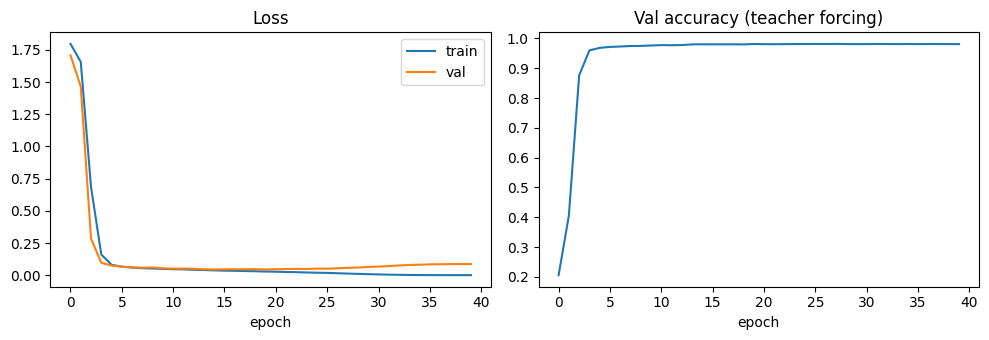

In [11]:
#Plot learning curve
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(history["val_acc"])
ax[1].set_title("Val accuracy (teacher forcing)"); ax[1].set_xlabel("epoch")
plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/ar_training_curves.png", dpi=150)
plt.show()

In [12]:
#real solving(generation) and evaluation
@torch.no_grad()
def generate(model, puz):                       # puz: (B, 36) on device
    model.eval()
    seq = torch.cat([puz, torch.full((puz.shape[0], 1), SEP, device=puz.device)], dim=1)
    for _ in range(NUM_CELLS):                  # 36 sequential steps
        logits = model(seq)[:, -1, :]           # scores for the next token
        nxt = logits[:, 1:N + 1].argmax(-1) + 1 # best digit among 1..6
        seq = torch.cat([seq, nxt[:, None]], dim=1)
    return seq[:, NUM_CELLS + 1:]               # the 36 generated cells

def evaluate(model, puz_np, sol_np, bs=500):
    puz = torch.tensor(puz_np.reshape(len(puz_np), -1), dtype=torch.long)
    preds = []
    if device.type == "cuda": torch.cuda.synchronize()
    t = time.time()
    for i in range(0, len(puz), bs):
        preds.append(generate(model, puz[i:i + bs].to(device)).cpu())
    if device.type == "cuda": torch.cuda.synchronize()
    elapsed = time.time() - t
    preds = torch.cat(preds).numpy().reshape(-1, N, N)
    sol_np = sol_np.astype(int); puz_np = puz_np.astype(int)
    metrics = {
        "cell_accuracy": float((preds == sol_np).mean()),
        "valid_solution_pct": float(np.mean([is_valid(p) for p in preds])),
        "exact_match_pct": float(np.mean([(p == s).all() for p, s in zip(preds, sol_np)])),
        "clues_kept_pct": float(np.mean([matches_clues(p, q) for p, q in zip(preds, puz_np)])),
        "avg_violations": float(np.mean([count_violations(p) for p in preds])),
        "forward_passes": NUM_CELLS,
        "ms_per_puzzle": elapsed / len(puz) * 1000,
    }
    return metrics, preds

model.load_state_dict(torch.load("checkpoints/ar_best.pt"))
metrics, preds = evaluate(model, te_p, te_s)
for k, v in metrics.items():
    print(f"{k:20s}: {v:.4f}")

cell_accuracy       : 0.8852
valid_solution_pct  : 0.6010
exact_match_pct     : 0.5310
clues_kept_pct      : 0.6970
avg_violations      : 1.4600
forward_passes      : 36.0000
ms_per_puzzle       : 9.1118


In [13]:
#Look at one example and save results
i = 0      # change this number to see other test puzzles
print("PUZZLE");       show(te_p[i].astype(int))
print("\nMODEL OUTPUT"); show(preds[i])
print("\nTRUTH");        show(te_s[i].astype(int))
print("\nRule violations in model output:", count_violations(preds[i]))

metrics["train_time_sec"] = train_time
json.dump(metrics, open("results/ar_metrics.json", "w"), indent=2)
np.save("results/ar_test_preds.npy", preds)
print("\nSaved: results/ar_metrics.json, results/ar_test_preds.npy")


PUZZLE
6 2 . | . 3 4 
. . 3 | . 2 . 
-------------
3 . . | . . 5 
1 5 . | 4 6 . 
-------------
. 3 5 | . 4 1 
. 1 . | . . 2 

MODEL OUTPUT
6 2 1 | 5 3 4 
5 4 3 | 1 2 6 
-------------
3 6 4 | 2 1 5 
1 5 2 | 4 6 3 
-------------
2 3 5 | 6 4 1 
4 1 6 | 3 5 2 

TRUTH
6 2 1 | 5 3 4 
5 4 3 | 1 2 6 
-------------
3 6 4 | 2 1 5 
1 5 2 | 4 6 3 
-------------
2 3 5 | 6 4 1 
4 1 6 | 3 5 2 

Rule violations in model output: 0

Saved: results/ar_metrics.json, results/ar_test_preds.npy


In [14]:
#re-evaluate with clue forcing
@torch.no_grad()
def generate_forced(model, puz):
    """Same as generate(), but given clues are copied, not predicted."""
    model.eval()
    seq = torch.cat([puz, torch.full((puz.shape[0], 1), SEP, device=puz.device)], dim=1)
    for i in range(NUM_CELLS):
        logits = model(seq)[:, -1, :]
        nxt = logits[:, 1:N + 1].argmax(-1) + 1
        clue = puz[:, i]                              # 0 if blank
        nxt = torch.where(clue > 0, clue, nxt)        # clue wins over the guess
        seq = torch.cat([seq, nxt[:, None]], dim=1)
    return seq[:, NUM_CELLS + 1:]

# evaluate() calls the global name `generate`, so we swap it temporarily
generate_free = generate
generate = generate_forced
metrics_f, preds_f = evaluate(model, te_p, te_s)
generate = generate_free            # put the original back

print(f"{'metric':20s} {'free':>10s} {'clue-forced':>12s}")
for k in metrics_f:
    print(f"{k:20s} {metrics[k]:10.4f} {metrics_f[k]:12.4f}")

metrics_f["train_time_sec"] = train_time
json.dump(metrics_f, open("results/ar_metrics_forced.json", "w"), indent=2)
np.save("results/ar_test_preds_forced.npy", preds_f)

metric                     free  clue-forced
cell_accuracy            0.8852       0.9013
valid_solution_pct       0.6010       0.5320
exact_match_pct          0.5310       0.5320
clues_kept_pct           0.6970       1.0000
avg_violations           1.4600       2.0930
forward_passes          36.0000      36.0000
ms_per_puzzle            9.1118       9.5695
